In [13]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import random_clifford, Operator
from qiskit_aer.noise import depolarizing_error
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

def execute_and_plot(circuit, shots):
    backend = AerSimulator()
    job_sim = backend.run(circuits=circuit, shots=shots)
    result = job_sim.result()
    counts = result.get_counts(circuit)
    return plot_histogram(counts)


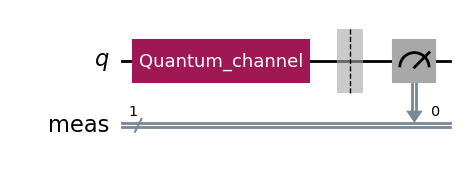

In [26]:
circuit = QuantumCircuit(1)

clifford = random_clifford(1)
clifford_dagger = clifford.adjoint()

clifford_circ = clifford.to_circuit()
clifford_dagger_circ = clifford_dagger.to_circuit()

circuit.compose(clifford_circ, inplace=True)

noisy_gate = depolarizing_error(0.1, 1).to_instruction()
circuit.append(noisy_gate, [0])

circuit.compose(clifford_dagger_circ, inplace=True)

circuit.measure_all()

circuit.draw("mpl")

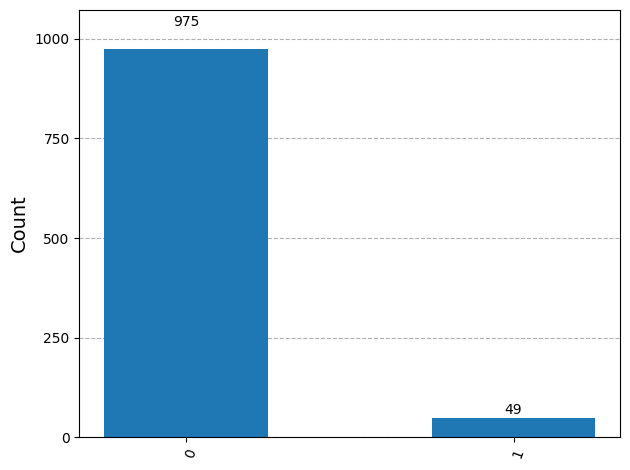

In [27]:
execute_and_plot(circuit=circuit, shots=1024)